# Small-Business Lending with Public Credit Guarantees: Default Models for 900,000 SBA Loans, a Great-Recession Out-of-Time Test and the Economics of the Guarantee

Small firms create most jobs but struggle to borrow, because they have short histories and little collateral. Public credit guarantees fix part of that by having the government absorb part of the lender's loss. To run such a scheme, the guarantor needs to know how risky each loan is, how much it loses when a loan fails, and how much of that loss it is taking off the banks. This notebook answers those questions on the largest guarantee programme in the world.

**What it does.** It models the default risk of U.S. small-business loans backed by the Small Business Administration's 7(a) guarantee programme, the template for many development-bank SME guarantee facilities. The notebook:

- trains logistic regression, LightGBM and a Keras network with embeddings on loans approved in fiscal years 1990–2004;
- tests them out of time on 2005–2010 approvals, the vintages that went through the Great Recession;
- estimates loss given default from charged-off principal;
- splits expected losses between the bank and the government according to the guaranteed share, and computes the break-even loan spread with and without the guarantee.

**Data.** The SBA national 7(a) loan dataset: 899,164 loans approved 1962–2014 (Kaggle `mirbektoktogaraev/should-this-loan-be-approved-or-denied`; Li, Mickel and Taylor, 2018, *Journal of Statistics Education*).

**Methods.** Out-of-time validation by approval vintage, class-weighted LightGBM, entity embeddings for state and industry, calibration by vintage, LGD estimation, an expected-loss split with risk-based pricing, and gain importance.

**Key output.** AUC and calibration by model and vintage, how the models handled the crisis, a data-leakage audit of the loan term, LGD by loan size, and how much expected loss the guarantee moves from banks to the government, by industry.

## 1. SME finance, credit guarantees and why default modelling matters

Small and medium enterprises create most jobs but find credit hard to get: they have short histories, little collateral and opaque accounts. **Public credit guarantees** address this market failure. The government (or a development bank) promises to pay a share of the lender's loss if the borrower defaults, so the bank lends to firms it would otherwise reject.

In the SBA 7(a) programme the guarantee is 50–85% of the loan. The guarantor needs to know three things:
1. **Probability of default (PD)** of each loan, to price the guarantee fee and to provision.
2. **Loss given default (LGD)**: here, charged-off principal divided by the amount disbursed.
3. **Expected loss (EL)** = PD × LGD × exposure, and how it is shared: the guarantor bears the guaranteed share *g*, the bank $1-g$.

The **break-even spread** a bank needs over its funding cost to cover its own expected loss is about $(1-g)\cdot\text{PD}\cdot\text{LGD}$ per year of risk. The guarantee therefore cuts the spread needed for a risky borrower by the factor $1-g$. This is the mechanism through which a guarantee scheme lowers the cost of credit.

**Out-of-time testing.** Credit models are built on past vintages and used on future ones. The 2005–2010 vintages were hit by the 2007–2009 recession, so a model trained on 1990–2004 is tested on exactly the kind of shift a guarantor fears.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("KERAS_BACKEND", "torch")

# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import keras
import lightgbm as lgb
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 149
rng = np.random.default_rng(SEED)
keras.utils.set_random_seed(SEED)
torch.set_num_threads(max(1, os.cpu_count() or 1))
KAGGLE_DATASET, FILE = (
    "mirbektoktogaraev/should-this-loan-be-approved-or-denied",
    "SBAnational.csv",
)
TRAIN_FY, TEST_FY = (1990, 2004), (2005, 2010)

print(
    f"lightgbm {lgb.__version__} · keras"
    f" {keras.__version__} ({keras.backend.backend()}) · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

…/site-packages/torch/cuda/__init__.py:68: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


lightgbm 4.7.0 · keras 3.15.1 (torch) · run on 2026-10-21


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


# --- Kaggle downloads
# The kaggle package authenticates with KAGGLE_API_TOKEN (read from .env above)
# or with
# ~/.kaggle/access_token / ~/.kaggle/kaggle.json. It is imported here, after
# load_dotenv, on purpose.
import zipfile


def kaggle_api():
    from kaggle.api.kaggle_api_extended import KaggleApi

    api = KaggleApi()
    api.authenticate()
    return api


def kaggle_file(ref, filename, competition=False):
    """
    Download one file of a Kaggle dataset or competition into data/ (once) and
    return its local path.
    """
    target = DATA_DIR / filename
    if target.exists():
        return target
    # files inside a dataset sub-folder arrive without it
    if (DATA_DIR / Path(filename).name).exists():
        return DATA_DIR / Path(filename).name
    api = kaggle_api()
    if competition:
        api.competition_download_file(ref, filename, path=DATA_DIR, quiet=True)
    else:
        api.dataset_download_file(ref, filename, path=DATA_DIR, quiet=True)
    zipped = DATA_DIR / f"{Path(filename).name}.zip"
    # large files arrive zipped
    if zipped.exists():
        with zipfile.ZipFile(zipped) as z:
            z.extractall(DATA_DIR)
        zipped.unlink()
    if not target.exists() and (DATA_DIR / Path(filename).name).exists():
        return DATA_DIR / Path(filename).name
    if not target.exists():
        raise FileNotFoundError(
            f"{filename} not found after download from {ref}"
        )
    return target

## 3. The loans and the features

**Outcome:** `MIS_Status` = `CHGOFF` (charged off, the default) or `P I F` (paid in full).

**Features known at approval:**
- log of the gross amount disbursed;
- SBA-guaranteed share (`SBA_Appv / GrAppv`);
- number of employees, new vs existing business, franchise, urban vs rural;
- revolving line of credit, LowDoc programme;
- industry (first two digits of NAICS), borrower state, whether the bank is in the same state;
- whether the loan was approved in a recession year (NBER: 1990–91, 2001, 2008–09).

Fields recorded after the outcome (charge-off date, charged-off amount, outstanding balance) are excluded from the features and used only for LGD.

**The loan term is excluded too, after a leakage check (next cell).** Most published models on this dataset use `Term` and report AUCs above 0.9. But 87% of loans repaid in full have a term that is a whole number of years (60, 84, 120 months…), against fewer than 10% of charged-off loans.

Contractual terms are set in whole years, so the term of a defaulted loan has evidently been overwritten after the event (with the months the loan actually ran, or similar). A feature that is rewritten by the outcome cannot be used at approval.

Vintages after 2010 are dropped: many of those loans had not matured by 2014, so a missing default is not a non-default.

In [3]:
raw = pd.read_csv(kaggle_file(KAGGLE_DATASET, FILE), low_memory=False)
money = lambda s: pd.to_numeric(
    s.astype(str).str.replace(r"[$,\s]", "", regex=True), errors="coerce"
)
df = raw.dropna(subset=["MIS_Status"]).copy()
for c in ["DisbursementGross", "GrAppv", "SBA_Appv", "ChgOffPrinGr"]:
    df[c] = money(df[c])
df["fy"] = pd.to_numeric(
    df["ApprovalFY"].astype(str).str.extract(r"(\d{4})")[0], errors="coerce"
)
df = df[
    df["fy"].between(TRAIN_FY[0], TEST_FY[1])
    & (df["DisbursementGross"] > 0)
    & (df["GrAppv"] > 0)
].copy()
df["y"] = (df["MIS_Status"] == "CHGOFF").astype(int)
df["guar_share"] = (df["SBA_Appv"] / df["GrAppv"]).clip(0, 1)
df["log_amt"] = np.log(df["DisbursementGross"])
df["size_band"] = pd.cut(
    df["DisbursementGross"],
    [0, 50e3, 150e3, 500e3, np.inf],
    labels=["< $50k", "$50k–150k", "$150k–500k", "> $500k"],
).astype(str)
df["new_business"] = (df["NewExist"] == 2).astype(int)
df["franchise"] = (~df["FranchiseCode"].isin([0, 1])).astype(int)
df["revolving"] = (df["RevLineCr"] == "Y").astype(int)
df["lowdoc"] = (df["LowDoc"] == "Y").astype(int)
df["sector"] = df["NAICS"].astype(str).str[:2].replace({"0": "unknown"})
df["same_state_bank"] = (df["State"] == df["BankState"]).astype(int)
df["recession_year"] = (
    df["fy"].isin([1990, 1991, 2001, 2008, 2009]).astype(int)
)
df["State"] = df["State"].fillna("NA")
df["lgd"] = (df["ChgOffPrinGr"] / df["DisbursementGross"]).clip(0, 1)
NUM = [
    "log_amt",
    "guar_share",
    "NoEmp",
    "new_business",
    "franchise",
    "UrbanRural",
    "revolving",
    "lowdoc",
    "same_state_bank",
    "recession_year",
]
CAT = ["sector", "State"]
TR = df[df["fy"].between(*TRAIN_FY)].reset_index(drop=True)
TE = df[df["fy"].between(*TEST_FY)].reset_index(drop=True)
VINT = df.groupby("fy").agg(
    loans=("y", "size"),
    default_rate=("y", "mean"),
    median_amount=("DisbursementGross", "median"),
    guar_share=("guar_share", "mean"),
)
print(
    f"{len(df):,} loans FY{TRAIN_FY[0]}–{TEST_FY[1]} · default rate"
    f" {df['y'].mean():.1%} · train {len(TR):,} ({TR['y'].mean():.1%}) · test"
    f" {len(TE):,} ({TE['y'].mean():.1%})"
)
VINT.round(3)

847,980 loans FY1990–2010 · default rate 17.5% · train 548,228 (9.0%) · test 299,752 (33.1%)


,loans,default_rate,median_amount,guar_share
fy,,,,
1990,14859,0.04,"150,000.00",0.85
1991,15660,0.03,"150,000.00",0.85
1992,20875,0.02,"170,000.00",0.85
1993,23299,0.02,"177,000.00",0.85
1994,31584,0.02,"150,000.00",0.83
1995,45688,0.03,"97,642.50",0.85
1996,40021,0.04,"100,000.00",0.79
1997,37718,0.06,"101,000.00",0.76
1998,36005,0.08,"116,000.00",0.76


In [4]:
whole_years = (df["Term"] % 12 == 0) & (df["Term"] > 0)
LEAK = df.groupby("y").agg(
    loans=("Term", "size"),
    median_term=("Term", "median"),
    share_whole_years=("Term", lambda t: ((t % 12 == 0) & (t > 0)).mean()),
)
LEAK.index = LEAK.index.map({0: "paid in full", 1: "charged off"})
print(
    "AUC of the term alone (shorter term = riskier), test vintages:"
    f" {roc_auc_score(df.loc[df['fy'] >= TEST_FY[0], 'y'], -df.loc[df['fy'] >= TEST_FY[0], 'Term']):.3f} ·"
    " a 'feature' this strong that is rewritten after default is leakage, so"
    " Term is not used"
)
LEAK.round(3)

AUC of the term alone (shorter term = riskier), test vintages: 0.811 · a 'feature' this strong that is rewritten after default is leakage, so Term is not used


,loans,median_term,share_whole_years
y,,,
paid in full,699620,84.00,0.86
charged off,148360,48.00,0.09


## 4. Default models

- **Logistic regression** with one-hot sectors and states.
- **LightGBM** with native categorical features, early-stopped on the 2004 vintage (held out of training).
- **Neural network** (Keras) with entity embeddings for sector (dimension 4) and state (dimension 6) and standardised numeric inputs.

Default is about 18% in training, so moderate class weights are enough. Predicted probabilities are recalibrated to the training default rate.

In [5]:
fit_m, val_m = TR["fy"] < TRAIN_FY[1], TR["fy"] == TRAIN_FY[1]
ytr, yte = TR["y"].values, TE["y"].values
S = {}
oh = pd.get_dummies(pd.concat([TR, TE])[NUM + CAT], columns=CAT, dtype=float)
mu, sd = oh.iloc[: len(TR)].mean(), oh.iloc[: len(TR)].std().replace(0, 1)
Z = ((oh - mu) / sd).fillna(0)
lr = LogisticRegression(C=0.1, max_iter=3000).fit(
    Z.iloc[: len(TR)].values, ytr
)
S["logistic"] = lr.predict_proba(Z.iloc[len(TR) :].values)[:, 1]

GX = pd.concat([TR, TE])[NUM + CAT].copy()
for c in CAT:
    GX[c] = GX[c].astype("category")
gtr, gte = GX.iloc[: len(TR)], GX.iloc[len(TR) :]
gbm = lgb.LGBMClassifier(
    n_estimators=3000,
    learning_rate=0.03,
    num_leaves=63,
    min_child_samples=200,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_lambda=2,
    cat_smooth=30,
    metric="auc",
    verbose=-1,
    random_state=SEED,
)
gbm.fit(
    gtr[fit_m.values],
    ytr[fit_m.values],
    eval_set=[(gtr[val_m.values], ytr[val_m.values])],
    eval_metric="auc",
    callbacks=[lgb.early_stopping(150, verbose=False)],
)
S["LightGBM"] = gbm.predict_proba(gte)[:, 1]

codes = {
    c: {v: i + 1 for i, v in enumerate(sorted(df[c].astype(str).unique()))}
    for c in CAT
}
nmu, nsd = TR[NUM].mean(), TR[NUM].std().replace(0, 1)
feed = lambda d: [
    ((d[NUM] - nmu) / nsd).fillna(0).values.astype("float32")
] + [
    d[c]
    .astype(str)
    .map(codes[c])
    .fillna(0)
    .values.reshape(-1, 1)
    .astype("int32")
    for c in CAT
]
n_in = keras.Input((len(NUM),))
c_in = [keras.Input((1,), dtype="int32") for _ in CAT]
emb = [
    keras.layers.Flatten()(keras.layers.Embedding(len(codes[c]) + 1, d)(i))
    for c, i, d in zip(CAT, c_in, [4, 6])
]
h = keras.layers.Concatenate()([n_in] + emb)
h = keras.layers.Dropout(0.2)(keras.layers.Dense(64, activation="relu")(h))
h = keras.layers.Dense(32, activation="relu")(h)
net = keras.Model(
    [n_in] + c_in, keras.layers.Dense(1, activation="sigmoid")(h)
)
net.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy",
    metrics=[keras.metrics.AUC(name="auc")],
)
net.fit(
    feed(TR[fit_m.values]),
    ytr[fit_m.values],
    validation_data=(feed(TR[val_m.values]), ytr[val_m.values]),
    epochs=15,
    batch_size=4096,
    verbose=0,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_auc",
            mode="max",
            patience=3,
            restore_best_weights=True,
        )
    ],
)
S["neural network (embeddings)"] = net.predict(
    feed(TE), batch_size=20000, verbose=0
).ravel()
print(f"LightGBM: {gbm.best_iteration_} trees")
RES = pd.DataFrame({
    m: {
        "AUC": roc_auc_score(yte, s),
        "PR-AUC": average_precision_score(yte, s),
        "Gini": 2 * roc_auc_score(yte, s) - 1,
        "mean PD": s.mean(),
        "actual default rate": yte.mean(),
    }
    for m, s in S.items()
}).T
RES.round(3)

LightGBM: 529 trees


,AUC,PR-AUC,Gini,mean PD,actual default rate
logistic,0.61,0.39,0.22,0.16,0.33
LightGBM,0.66,0.46,0.32,0.14,0.33
neural network (embeddings),0.68,0.48,0.36,0.16,0.33


## 5. The crisis vintages: ranking vs calibration

A model can keep ranking borrowers well while the **level** of defaults moves with the economy. The table shows, by approval vintage, the AUC and the ratio of predicted to actual default rate. Loans approved in 2005–2007 were disbursed just before the recession and defaulted much more often than anything in the training period.

In [6]:
best = RES["AUC"].idxmax()
BYV = (
    TE.assign(p=S[best])
    .groupby("fy")
    .apply(
        lambda g: pd.Series({
            "loans": len(g),
            "actual default rate": g["y"].mean(),
            "predicted PD": g["p"].mean(),
            "predicted / actual": g["p"].mean() / g["y"].mean(),
            "AUC": roc_auc_score(g["y"], g["p"]),
        }),
        include_groups=False,
    )
)
BYV.round(3)

,loans,actual default rate,predicted PD,predicted / actual,AUC
fy,,,,,
2005,"76,958.00",0.25,0.16,0.65,0.68
2006,"75,756.00",0.35,0.16,0.47,0.67
2007,"71,649.00",0.43,0.17,0.40,0.67
2008,"39,458.00",0.41,0.14,0.34,0.68
2009,"19,103.00",0.21,0.11,0.54,0.69
2010,"16,828.00",0.14,0.11,0.80,0.62


## 6. Loss given default and the guarantee split

LGD is estimated on charged-off **training** loans as charged-off principal divided by the amount disbursed, by loan size band and sector. For every test loan:
- expected loss $\text{EL}=\text{PD}\times\text{LGD}\times\text{disbursed}$;
- the guarantor's share $g\cdot\text{EL}$ and the bank's share $(1-g)\cdot\text{EL}$;
- the bank's break-even annual spread with the guarantee, $(1-g)\cdot\text{PD}\cdot\text{LGD}/\text{life}$, and without it, $\text{PD}\cdot\text{LGD}/\text{life}$, with an average life of half the contractual term (amortising loans). Because the recorded term of defaulted loans is unreliable, the term used is the median term of loans **repaid in full** in the same sector during the training period.

The calculation uses the out-of-time PDs, rescaled so their average matches each vintage's realised default rate. That isolates the allocation effect from the crisis level shift seen above.

In [7]:
lgd_tab = (
    TR[TR["y"] == 1]
    .groupby("size_band")["lgd"]
    .agg(["mean", "median", "count"])
    .reindex(["< $50k", "$50k–150k", "$150k–500k", "> $500k"])
)
lgd_map = TR[TR["y"] == 1].groupby(["size_band", "sector"])["lgd"].mean()
lgd_re = TR[TR["y"] == 1].groupby("size_band")["lgd"].mean()
term_pif = TR[TR["y"] == 0].groupby("sector")["Term"].median()
T2 = TE.assign(p=S[best])
T2["p_adj"] = (
    T2["p"]
    * T2.groupby("fy")["y"].transform("mean")
    / T2.groupby("fy")["p"].transform("mean")
)
T2["lgd_hat"] = [
    lgd_map.get((r, s), lgd_re[r])
    for r, s in zip(T2["size_band"], T2["sector"])
]
T2["el"] = T2["p_adj"] * T2["lgd_hat"] * T2["DisbursementGross"]
T2["el_guarantor"], T2["el_bank"] = T2["el"] * T2["guar_share"], T2["el"] * (
    1 - T2["guar_share"]
)
life = (
    T2["sector"].map(term_pif).fillna(TR.loc[TR["y"] == 0, "Term"].median())
    / 24
).clip(lower=0.5)
T2["spread_no_guar_bp"] = 1e4 * T2["p_adj"] * T2["lgd_hat"] / life
T2["spread_with_guar_bp"] = T2["spread_no_guar_bp"] * (1 - T2["guar_share"])
T2["actual_loss"] = T2["ChgOffPrinGr"].fillna(0) * T2["y"]
SECT = T2.groupby("sector").agg(
    loans=("y", "size"),
    default_rate=("y", "mean"),
    EL_bn=("el", lambda s: s.sum() / 1e9),
    actual_loss_bn=("actual_loss", lambda s: s.sum() / 1e9),
    guarantor_share=("el_guarantor", "sum"),
    bank_share=("el_bank", "sum"),
    spread_no_guar_bp=("spread_no_guar_bp", "median"),
    spread_with_guar_bp=("spread_with_guar_bp", "median"),
)
SECT["guarantor share of EL"] = SECT["guarantor_share"] / (
    SECT["guarantor_share"] + SECT["bank_share"]
)
SECT = SECT.drop(columns=["guarantor_share", "bank_share"]).sort_values(
    "EL_bn", ascending=False
)
print(
    f"Test portfolio: EL ${T2['el'].sum() / 1e9:,.2f}bn vs actual charged-off"
    f" principal ${T2['actual_loss'].sum() / 1e9:,.2f}bn · guarantor bears"
    f" {T2['el_guarantor'].sum() / T2['el'].sum():.0%} of EL"
)
lgd_tab.round(3)

Test portfolio: EL $6.02bn vs actual charged-off principal $6.45bn · guarantor bears 64% of EL


,mean,median,count
size_band,,,
< $50k,0.67,0.72,18334
$50k–150k,0.58,0.60,16537
$150k–500k,0.55,0.56,10284
> $500k,0.53,0.53,4018


In [8]:
SECT.head(12).round(3)

,loans,default_rate,EL_bn,actual_loss_bn,spread_no_guar_bp,spread_with_guar_bp,guarantor share of EL
sector,,,,,,,
72,32014,0.32,0.94,1.07,398.27,127.13,0.70
44,35370,0.36,0.86,0.96,589.37,221.44,0.66
23,33159,0.36,0.59,0.64,543.85,244.51,0.58
81,28027,0.34,0.48,0.58,379.45,150.26,0.64
54,32027,0.31,0.43,0.48,445.57,189.36,0.59
42,18132,0.36,0.42,0.42,547.87,235.65,0.61
45,15944,0.39,0.33,0.33,744.15,275.82,0.63
33,12986,0.24,0.32,0.27,429.34,166.32,0.65
62,19700,0.19,0.30,0.32,230.73,87.22,0.66


## 7. Charts and dashboard

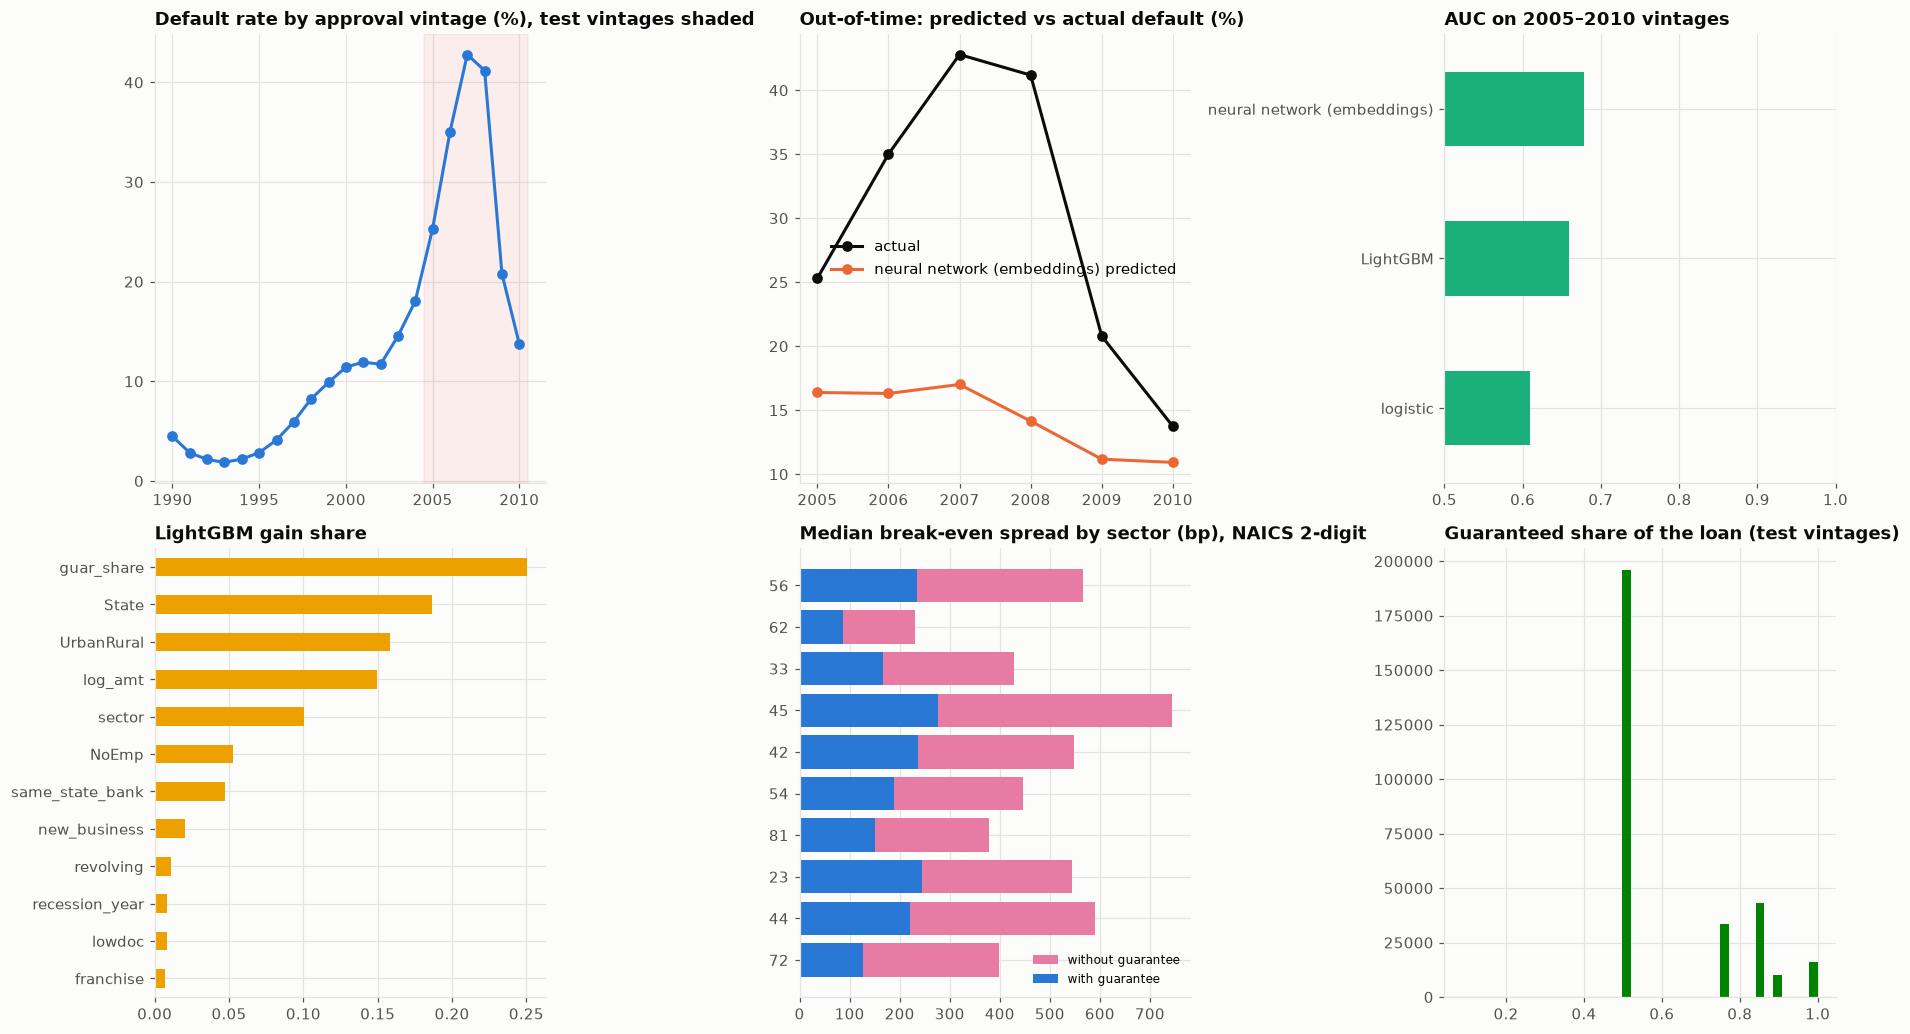

In [9]:
IMP = pd.Series(
    gbm.booster_.feature_importance("gain"), index=NUM + CAT
).sort_values()
fig, ax = plt.subplots(2, 3, figsize=(17, 9.5))
a = ax[0, 0]
a.plot(VINT.index, VINT["default_rate"] * 100, marker="o", color=PALETTE[0])
a.axvspan(TEST_FY[0] - 0.5, TEST_FY[1] + 0.5, color=STATUS["red"], alpha=0.08)
a.set_title("Default rate by approval vintage (%), test vintages shaded")
a = ax[0, 1]
a.plot(
    BYV.index,
    BYV["actual default rate"] * 100,
    marker="o",
    color=INK,
    label="actual",
)
a.plot(
    BYV.index,
    BYV["predicted PD"] * 100,
    marker="o",
    color=PALETTE[1],
    label=f"{best} predicted",
)
a.legend()
a.set_title("Out-of-time: predicted vs actual default (%)")
a = ax[0, 2]
RES["AUC"].sort_values().plot.barh(ax=a, color=PALETTE[2])
a.set_xlim(0.5, 1)
a.set_title("AUC on 2005–2010 vintages")
a = ax[1, 0]
(IMP / IMP.sum()).plot.barh(ax=a, color=PALETTE[3])
a.set_title("LightGBM gain share")
a = ax[1, 1]
s12 = SECT.head(10)
a.barh(
    s12.index,
    s12["spread_no_guar_bp"],
    color=PALETTE[4],
    label="without guarantee",
)
a.barh(
    s12.index,
    s12["spread_with_guar_bp"],
    color=PALETTE[0],
    label="with guarantee",
)
a.legend(fontsize=8)
a.set_title("Median break-even spread by sector (bp), NAICS 2-digit")
a = ax[1, 2]
a.hist(T2["guar_share"], bins=40, color=PALETTE[5])
a.set_title("Guaranteed share of the loan (test vintages)")
fig.tight_layout()
save_fig(fig, "01_sme_guarantees")
plt.show()

In [10]:
dash = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=(
        "Default rate by vintage",
        "Predicted vs actual default (test vintages)",
        "AUC by model",
        "Break-even spread by sector (bp)",
    ),
)
dash.add_trace(
    go.Scatter(
        x=VINT.index,
        y=VINT["default_rate"],
        mode="lines+markers",
        line=dict(color=PALETTE[0]),
        showlegend=False,
    ),
    1,
    1,
)
dash.add_trace(
    go.Scatter(
        x=BYV.index,
        y=BYV["actual default rate"],
        name="actual",
        line=dict(color=INK),
    ),
    1,
    2,
)
dash.add_trace(
    go.Scatter(
        x=BYV.index,
        y=BYV["predicted PD"],
        name="predicted",
        line=dict(color=PALETTE[1]),
    ),
    1,
    2,
)
dash.add_trace(
    go.Bar(
        x=RES.index, y=RES["AUC"], marker_color=PALETTE[2], showlegend=False
    ),
    2,
    1,
)
dash.add_trace(
    go.Bar(
        x=s12.index,
        y=s12["spread_no_guar_bp"],
        name="without guarantee",
        marker_color=PALETTE[4],
    ),
    2,
    2,
)
dash.add_trace(
    go.Bar(
        x=s12.index,
        y=s12["spread_with_guar_bp"],
        name="with guarantee",
        marker_color=PALETTE[0],
    ),
    2,
    2,
)
dash.update_layout(
    height=900,
    width=1400,
    template="simple_white",
    title="SME lending with public guarantees: SBA 7(a) loans",
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 8. Reading the results and limitations

**The sample.** 847,980 SBA 7(a) loans approved in fiscal years 1990–2010. Training uses 1990–2004 vintages (default rate 9.0%); the out-of-time test uses 2005–2010 (33.1%). The 2005–2008 vintages, disbursed just before the Great Recession, defaulted at 25–43%, three to four times anything seen in training.

**A leakage audit changes the headline.** The loan term alone ranks the test loans with an AUC of 0.81. But 86% of repaid loans have a term in whole years, against 9% of charged-off loans: the recorded term of defaulted loans has evidently been rewritten after the event.

Models that include it reach AUCs above 0.9 on this dataset, a result often reported, and an artefact. Without it, the honest numbers are:

| Model | AUC | PR-AUC | Mean PD | Actual default rate |
| --- | --- | --- | --- | --- |
| Logistic regression | 0.61 | 0.39 | 16% | 33% |
| LightGBM | 0.66 | 0.46 | 14% | 33% |
| Neural network with state and industry embeddings | **0.68** | **0.48** | 16% | 33% |

At origination, the information in the file (size, guarantee share, employees, new business, franchise, urban/rural, revolving line, LowDoc, industry, state, same-state bank) separates small-business risk only moderately. That is consistent with small-business lending being notoriously hard to score without financial statements or bank-account data. The embedding network does best, because industry × state carries much of the signal.

**Ranking survived the crisis; calibration did not.**
- The AUC stays at 0.67–0.69 for every vintage from 2005 to 2009, so the ordering of borrowers held up.
- Predicted default rates were 14–17%, against 25–43% realised: the model under-predicted by a factor of 1.5 to 2.9 for the 2005–2008 vintages. A PD model calibrated on a benign period understates losses in a downturn. This is why IFRS 9 and CECL require forward-looking macro overlays, and Basel requires downturn LGD and through-the-cycle PDs.

**The guarantee's economics.**
- LGD on charged-off training loans (charged-off principal / amount disbursed) falls with loan size, from 67% under $50k to 53% above $500k. Small loans are mostly unsecured working capital.
- With PDs rescaled to each vintage's realised level, expected loss on the 2005–2010 portfolio is $6.0 billion, against $6.45 billion actually charged off. **The SBA's guarantee absorbs 64% of it**, between 58% and 70% depending on the industry.
- Break-even credit spreads (over funding, with an average life of half the contractual term) fall with the guarantee from 230–744 bp to 87–276 bp. Restaurants and hotels (NAICS 72) fall from 398 to 127 bp, and transport and warehousing (48) from 615 to 257 bp. Spreads of 400–700 bp without a guarantee would price many small firms out. With it, they fall to levels a bank can charge. This is the mechanism through which public guarantee schemes widen access to credit.

**Limitations**
- The dataset has no borrower financials, credit scores or bank-account data. Real SME scorecards use them and would score much better.
- Default is a final charge-off. Loans that were restructured or repurchased by the SBA without a charge-off count as repaid.
- Spreads ignore funding, capital and operating costs. They show only how the guarantee changes the expected-loss component.
- The guarantee split assumes the SBA bears its guaranteed share of every loss *pari passu* with the bank, which is how 7(a) works, but recoveries and the SBA's upfront and annual guarantee fees are not modelled.

In [11]:
RES.to_csv(OUT_DIR / "model_scores_out_of_time.csv")
BYV.to_csv(OUT_DIR / "calibration_by_vintage.csv")
VINT.to_csv(OUT_DIR / "vintages.csv")
lgd_tab.to_csv(OUT_DIR / "lgd_by_loan_size.csv")
LEAK.to_csv(OUT_DIR / "term_leakage_check.csv")
SECT.to_csv(OUT_DIR / "guarantee_economics_by_sector.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_sme_guarantees.png, calibration_by_vintage.csv, dashboard.html, dashboard.png, guarantee_economics_by_sector.csv, lgd_by_collateral.csv, lgd_by_loan_size.csv, model_scores_out_of_time.csv, term_leakage_check.csv, vintages.csv


## References

### Finance and regulation

- Li, M., Mickel, A., & Taylor, S. (2018). "Should this loan be approved or denied?": A large dataset with class assignment guidelines. *Journal of Statistics Education, 26*(1), 55–66. https://doi.org/10.1080/10691898.2018.1434342
- Beck, T., Klapper, L. F., & Mendoza, J. C. (2010). The typology of partial credit guarantee funds around the world. *Journal of Financial Stability, 6*(1), 10–25. https://doi.org/10.1016/j.jfs.2008.12.003
- Honohan, P. (2010). Partial credit guarantees: Principles and practice. *Journal of Financial Stability, 6*(1), 1–9. https://doi.org/10.1016/j.jfs.2009.05.008
- Glennon, D., & Nigro, P. (2005). Measuring the default risk of small business loans: A survival analysis approach. *Journal of Money, Credit and Banking, 37*(5), 923–947. https://doi.org/10.1353/mcb.2005.0051
- Altman, E. I., & Sabato, G. (2007). Modelling credit risk for SMEs: Evidence from the U.S. market. *Abacus, 43*(3), 332–357. https://doi.org/10.1111/j.1467-6281.2007.00234.x

### Machine learning and deep learning

- Guo, C., & Berkhahn, F. (2016). Entity embeddings of categorical variables. *arXiv*. https://arxiv.org/abs/1604.06737
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*. https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html
- Kaufman, S., Rosset, S., Perlich, C., & Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM Transactions on Knowledge Discovery from Data, 6*(4), 1–21. https://doi.org/10.1145/2382577.2382579
- Chollet, F., et al. (2015). *Keras*. https://keras.io